# Industry Project: Containerizing an ML Service (Production-Style)

> **Who is this notebook for?** Someone who knows roughly what Docker is and has seen a Dockerfile, but has never
> shipped a container that a platform team would accept into production. Every step is explained in plain English,
> and almost every line of code has a comment.
>
> **No Docker needed to run this notebook.** We generate a complete, real project into a temporary folder,
> test the app in Python, and **check the Dockerfile and compose file against best-practice rules with Python code**.
> The `docker build` / `docker run` commands are printed for you to run yourself; the one cell that could run them
> is switched off unless you set `RUN_DOCKER=1`.

---

### How this notebook is different from the others in `17_Docker/`

| `01`-`03` and `kubernetes/` | This notebook |
|---|---|
| Reference Dockerfiles and commands, explained piece by piece | Generates a **complete project** (app, model, pinned requirements, Dockerfile, `.dockerignore`, compose file, tests) |
| "Pin versions", "use slim", "non-root user" as advice | A small **Dockerfile linter** in Python that checks those rules, run on a good and a bad Dockerfile |
| Image sizes quoted from memory | Image-size **estimate built from measured numbers**: the real dependency tree of this environment + base-image sizes from Docker Hub |
| "Order layers for caching" | A **layer-cache simulation** showing how many seconds each code change costs in CI |
| Commands to copy | Commands plus an opt-in, guarded cell (`RUN_DOCKER=1`) |

---

### The business problem

Your team built a **house-price estimation API** for a real-estate website. The platform team will only deploy containers that pass their checklist:

| Platform requirement | Why they insist |
|---|---|
| Base image **pinned** to an exact version, never `latest` | A rebuild next month must produce the same software |
| **Non-root** user | If the app is hacked, the attacker is not root in the container |
| **No secrets** baked into the image | Images are copied to registries, laptops and CI caches; secrets leak |
| **Health check** endpoints | The orchestrator must know when to restart or stop routing traffic |
| **Small image** | Faster pulls = faster autoscaling and deploys; smaller attack surface |
| **Fast rebuilds** in CI | A one-line code fix must not re-download 150 MB of packages |
| Config via **environment variables** | The same image runs in staging and production |

Success = a project that passes all automated checks and can be built and run with three commands.

---

### Table of Contents
1. Setup and config
2. The model artifact
3. The application code (generated)
4. Pinned requirements and the real dependency tree
5. The multi-stage Dockerfile
6. `.dockerignore` and docker-compose
7. Test the generated app in Python (no container needed)
8. A Dockerfile linter: checking best-practice rules in code
9. Validate requirements, `.dockerignore` and compose
10. Build context: what `.dockerignore` saves
11. Layer caching: how much each change costs to rebuild
12. Image size trade-offs: full vs. slim vs. alpine
13. The exact build / run / test commands (opt-in execution)
14. From container to Kubernetes, checklist, exercises and resources

---
## 1. Setup and config

The base image tag is the single most important line of a Dockerfile, so it lives in the config. `python:3.12.15-slim-trixie` means: Python **3.12.15** exactly, the **slim** variant (no compilers, no docs), on Debian 13 "**trixie**". The tag was checked on Docker Hub on 2026-10-21; check for a newer patch release when you use this notebook. Production teams go one step further and pin the **digest** (`python:3.12.15-slim-trixie@sha256:...`), which can never change, and let a bot (Dependabot, Renovate) propose updates.

In [1]:
import gzip                              # estimate compressed (download) sizes
import importlib                         # import the generated app like any Python package
import json
import logging
import os
import re                                # simple pattern rules for the linter
import shlex                             # print shell commands safely quoted
import subprocess                        # only used if RUN_DOCKER=1
import sys
import tempfile                          # the generated project lives in a temp folder, never in the repo
import textwrap
import warnings
from dataclasses import dataclass
from fnmatch import fnmatch              # .dockerignore-style pattern matching
from importlib import metadata           # versions and file lists of installed packages
from pathlib import Path

warnings.filterwarnings("ignore")        # must come before fastapi.testclient (it warns about httpx on import)
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import yaml                              # validate docker-compose.yml
from packaging.requirements import Requirement
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("containerize")
logging.getLogger("httpx").setLevel(logging.WARNING)       # TestClient logs every request through httpx; too noisy


@dataclass(frozen=True)
class ProjectConfig:
    name: str = "house-price-api"
    version: str = "1.0.0"
    python_image: str = "python:3.12.15-slim-trixie"      # pinned base image (checked on Docker Hub 2026-10-21)
    registry: str = "registry.example.com/ml"             # placeholder registry
    port: int = 8000
    uid: int = 10001                                       # fixed, non-root user ID (>10000 avoids host-user clashes)


CFG = ProjectConfig()
RUN_DOCKER = os.environ.get("RUN_DOCKER") == "1"          # default OFF: this notebook never builds or runs containers
PROJECT = Path(tempfile.mkdtemp(prefix="containerize_")) / CFG.name   # in real life: your git repository
PROJECT.mkdir(parents=True)
IMAGE = f"{CFG.registry}/{CFG.name}:{CFG.version}"


def write(rel_path: str, content: str) -> Path:
    """Write a project file (dedented) and return its path."""
    path = PROJECT / rel_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(textwrap.dedent(content).lstrip("\n"))
    return path


print("project folder:", PROJECT)
print("image name    :", IMAGE, "| RUN_DOCKER =", RUN_DOCKER)

project folder: /tmp/containerize_ntxjkyfr/house-price-api
image name    : registry.example.com/ml/house-price-api:1.0.0 | RUN_DOCKER = False


---
## 2. The model artifact

We train a small model on the California housing dataset (bundled with scikit-learn, cached locally) and save it **inside the project** under `models/`. The model takes the 8 numeric features in a fixed order and predicts the median house value.

> **Bake the model into the image, or load it at startup?**
> | | Bake in (`COPY models/`) | Load at startup (volume / S3 / registry) |
> |---|---|---|
> | Good for | small models (KB to a few hundred MB) | large models (GBs), frequent model updates |
> | Pro | image = code + model, perfectly reproducible, no network at startup | small image, update the model without rebuilding |
> | Con | every model update is a new image | startup depends on storage; must version the model separately |
>
> Our model is tiny, so we bake it in, but the app reads `MODEL_PATH` from the environment so a mounted model can override it (the approach shown in `02_docker_for_ml.ipynb` for big models).

In [2]:
housing = fetch_california_housing()                          # from ~/scikit_learn_data (no download if cached)
FEATURES = list(housing.feature_names)                        # the column ORDER the model expects
X_train, X_test, y_train, y_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)

model = Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=1.0))]).fit(X_train, y_train)
mae_usd = mean_absolute_error(y_test, model.predict(X_test)) * 100_000          # target is in $100k units
baseline_usd = mean_absolute_error(y_test, np.full_like(y_test, y_train.mean())) * 100_000

(PROJECT / "models").mkdir()
joblib.dump(model, PROJECT / "models" / "model.joblib")
(PROJECT / "models" / "metadata.json").write_text(json.dumps({
    "model_version": CFG.version, "features": FEATURES, "sklearn_version": sklearn.__version__,
    "test_mae_usd": round(mae_usd)}, indent=2))
print(f"Ridge MAE ${mae_usd:,.0f} vs. predict-the-mean baseline ${baseline_usd:,.0f}")
print("features:", FEATURES)

Ridge MAE $53,319 vs. predict-the-mean baseline $90,607
features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


A linear model is far from the best possible here (tree ensembles do much better on this dataset), but it beats the baseline, it is tiny and it needs no extra libraries. The point of this notebook is the **container**, not the model.

---
## 3. The application code (generated)

A compact version of the production API from `../12_FastAPI/04_industry_production_ml_api.ipynb`: settings from environment variables, model loaded once in the `lifespan`, liveness and readiness endpoints, a validated `/v1/predict`. Two container-specific details:
- **No pandas**: the app sends a NumPy array in the training column order. Every dependency you don't install is megabytes you don't ship and a CVE you don't have to patch.
- Logs go to **stdout** (`PYTHONUNBUFFERED=1` in the Dockerfile): in containers you never write log files; the platform collects stdout.

In [3]:
write("app/__init__.py", "")
write("app/main.py", """
    # House-price estimation API. Configuration comes ONLY from environment variables.
    import json
    import logging
    import os
    from contextlib import asynccontextmanager
    from pathlib import Path

    import joblib
    import numpy as np
    from fastapi import FastAPI, HTTPException, Request
    from pydantic import BaseModel, Field

    MODEL_PATH = Path(os.environ.get("MODEL_PATH", "models/model.joblib"))
    LOG_LEVEL = os.environ.get("LOG_LEVEL", "INFO").upper()
    logging.basicConfig(level=LOG_LEVEL, format="%(asctime)s %(levelname)s %(name)s %(message)s")
    log = logging.getLogger("house_api")


    class House(BaseModel):
        median_income: float = Field(gt=0, le=20, description="Block median income in $10k")
        house_age: float = Field(ge=0, le=100)
        avg_rooms: float = Field(gt=0, le=50)
        avg_bedrooms: float = Field(gt=0, le=20)
        population: float = Field(ge=1, le=50_000)
        avg_occupancy: float = Field(gt=0, le=50)
        latitude: float = Field(ge=32, le=42.5)          # California only
        longitude: float = Field(ge=-124.5, le=-114)

        def to_row(self) -> list:                       # same order as the model's training columns
            return [self.median_income, self.house_age, self.avg_rooms, self.avg_bedrooms,
                    self.population, self.avg_occupancy, self.latitude, self.longitude]


    @asynccontextmanager
    async def lifespan(app: FastAPI):
        app.state.model, app.state.meta = None, {}
        try:
            app.state.model = joblib.load(MODEL_PATH)
            app.state.meta = json.loads((MODEL_PATH.parent / "metadata.json").read_text())
            log.info("model loaded from %s (version %s)", MODEL_PATH, app.state.meta.get("model_version"))
        except Exception as exc:                        # stay alive, report not ready
            log.error("model load failed: %s", exc)
        yield


    app = FastAPI(title="House Price API", lifespan=lifespan)


    @app.get("/health/live")
    def live():
        return {"status": "alive"}


    @app.get("/health/ready")
    def ready(request: Request):
        if request.app.state.model is None:
            raise HTTPException(status_code=503, detail="model not loaded")
        return {"status": "ready", "model_version": request.app.state.meta.get("model_version")}


    @app.post("/v1/predict")
    def predict(house: House, request: Request):
        if request.app.state.model is None:
            raise HTTPException(status_code=503, detail="model not loaded")
        value = float(request.app.state.model.predict(np.array([house.to_row()]))[0]) * 100_000
        return {"predicted_value_usd": round(max(value, 0.0), -2),
                "model_version": request.app.state.meta.get("model_version")}
""")

write("tests/__init__.py", "")
write("tests/test_smoke.py", """
    # Smoke tests: run in CI against the code (pytest) and, via curl, against the built image.
    from fastapi.testclient import TestClient

    from app.main import app

    EXAMPLE = {"median_income": 8.3, "house_age": 41, "avg_rooms": 6.9, "avg_bedrooms": 1.0,
               "population": 322, "avg_occupancy": 2.6, "latitude": 37.88, "longitude": -122.23}


    def test_ready_and_predict():
        with TestClient(app) as client:
            assert client.get("/health/ready").status_code == 200
            response = client.post("/v1/predict", json=EXAMPLE)
            assert response.status_code == 200 and response.json()["predicted_value_usd"] > 0


    def test_rejects_location_outside_california():
        with TestClient(app) as client:
            assert client.post("/v1/predict", json={**EXAMPLE, "latitude": 51.5}).status_code == 422
""")
print((PROJECT / "app" / "main.py").read_text()[:400], "...")

# House-price estimation API. Configuration comes ONLY from environment variables.
import json
import logging
import os
from contextlib import asynccontextmanager
from pathlib import Path

import joblib
import numpy as np
from fastapi import FastAPI, HTTPException, Request
from pydantic import BaseModel, Field

MODEL_PATH = Path(os.environ.get("MODEL_PATH", "models/model.joblib"))
LOG_LEVEL = os.e ...


---
## 4. Pinned requirements and the real dependency tree

`requirements.txt` lists what the app imports, pinned with `==` to **the exact versions we trained and tested with**. For ML this is not optional: a model pickled with scikit-learn 1.9 may load incorrectly, or not at all, under another version.

But your 5 direct dependencies pull in more packages (FastAPI needs Starlette and Pydantic; scikit-learn needs SciPy...). Below we walk the **real dependency tree of this Python environment** using package metadata. Teams freeze that full tree in a **lock file** (`pip-compile --generate-hashes`, `uv pip compile`, `poetry.lock`) so that even indirect dependencies can't change silently between builds.

In [4]:
DIRECT = ["fastapi", "uvicorn", "pydantic", "scikit-learn", "numpy", "joblib"]


def canonical(name: str) -> str:
    return re.sub(r"[-_.]+", "-", name).lower()                   # "scikit_learn" == "scikit-learn"


def dependency_closure(roots: list[str]) -> dict:
    """All installed packages needed by `roots` (ignores optional extras). Returns {name: Distribution}."""
    found, stack = {}, list(roots)
    while stack:
        name = canonical(stack.pop())
        if name in found:
            continue
        try:
            dist = metadata.distribution(name)
        except metadata.PackageNotFoundError:                    # required but not installed here: report it
            log.warning("dependency %s is not installed in this environment", name)
            continue
        found[name] = dist
        for req_text in dist.requires or []:
            req = Requirement(req_text)
            if req.marker is None or req.marker.evaluate({"extra": ""}):   # skip "extra == ..." deps
                stack.append(req.name)
    return found


closure = dependency_closure(DIRECT)
write("requirements.txt", "\n".join(f"{n}=={metadata.version(n)}" for n in DIRECT) + "\n")
write("requirements.lock", "# full pinned tree (in real projects generated by pip-compile / uv with --generate-hashes)\n"
      + "\n".join(f"{n}=={d.version}" for n, d in sorted(closure.items())) + "\n")
write("requirements-dev.txt", "-r requirements.txt\npytest==8.4.2\nhttpx==0.28.1\n")
print("requirements.txt:\n" + (PROJECT / "requirements.txt").read_text())
print(f"{len(DIRECT)} direct dependencies -> {len(closure)} packages in total:", ", ".join(sorted(closure)))

requirements.txt:
fastapi==0.138.1
uvicorn==0.49.0
pydantic==2.13.4
scikit-learn==1.9.0
numpy==2.4.6
joblib==1.5.3

6 direct dependencies -> 19 packages in total: annotated-doc, annotated-types, anyio, click, fastapi, h11, idna, joblib, narwhals, numpy, pydantic, pydantic-core, scikit-learn, scipy, starlette, threadpoolctl, typing-extensions, typing-inspection, uvicorn


---
## 5. The multi-stage Dockerfile

Read it top to bottom; every line answers one of the platform requirements. Key ideas:

1. **Multi-stage build.** Stage `builder` creates a virtual environment in `/opt/venv` and installs the packages. Stage `runtime` starts again from the clean base image and copies **only** `/opt/venv`. Anything needed only for building (pip caches, compilers if a package needs compiling) never reaches the final image.
2. **Layer order = cache efficiency.** Docker caches every instruction. Things that change rarely (base image, `requirements.txt` + `pip install`) come first; things that change often (your code) come last. A code change then rebuilds only the last cheap layers (Section 11 measures this).
3. **Non-root with a fixed UID** (`10001`). Kubernetes can enforce `runAsNonRoot`; a numeric `USER` makes that check possible.
4. **`HEALTHCHECK` with Python**, because slim images have no `curl` (and installing it adds size and attack surface).
5. **Exec-form `CMD`** (`["uvicorn", ...]`): uvicorn runs as PID 1 and receives `SIGTERM` directly, so it can finish in-flight requests on shutdown. The shell form (`CMD uvicorn ...`) wraps it in `/bin/sh`, which does not forward signals: the container gets killed hard after the timeout.
6. **Worker count from the environment**: uvicorn reads `WEB_CONCURRENCY` for `--workers`. On Kubernetes, many teams use 1 worker per container and scale with more pods instead (FastAPI docs, "FastAPI in Containers").

In [5]:
DOCKERFILE = write("Dockerfile", f"""
    # syntax=docker/dockerfile:1
    # ---- Base image pinned to an exact version (better still: add @sha256:<digest>) ----
    ARG PYTHON_IMAGE={CFG.python_image}

    # ===================== Stage 1: builder =====================
    FROM ${{PYTHON_IMAGE}} AS builder
    ENV PIP_NO_CACHE_DIR=1 \\
        PIP_DISABLE_PIP_VERSION_CHECK=1
    RUN python -m venv /opt/venv
    ENV PATH="/opt/venv/bin:$PATH"
    # Dependencies first: this layer is cached until requirements.txt changes
    COPY requirements.txt .
    RUN pip install --no-cache-dir -r requirements.txt

    # ===================== Stage 2: runtime =====================
    FROM ${{PYTHON_IMAGE}} AS runtime
    LABEL org.opencontainers.image.title="{CFG.name}" \\
          org.opencontainers.image.version="{CFG.version}" \\
          org.opencontainers.image.source="https://git.example.com/ml/{CFG.name}"
    ENV PYTHONDONTWRITEBYTECODE=1 \\
        PYTHONUNBUFFERED=1 \\
        PATH="/opt/venv/bin:$PATH" \\
        MODEL_PATH=/app/models/model.joblib \\
        WEB_CONCURRENCY=2
    # Non-root user with a fixed numeric UID/GID
    RUN groupadd --system --gid {CFG.uid} app \\
     && useradd --system --uid {CFG.uid} --gid app --no-create-home app
    WORKDIR /app
    COPY --from=builder /opt/venv /opt/venv
    # Rarely-changing files first, code last (cache!)
    COPY --chown=app:app models/ ./models/
    COPY --chown=app:app app/ ./app/
    USER {CFG.uid}
    EXPOSE {CFG.port}
    HEALTHCHECK --interval=30s --timeout=3s --start-period=20s --retries=3 \\
      CMD ["python", "-c", "import sys, urllib.request; sys.exit(0 if urllib.request.urlopen('http://127.0.0.1:{CFG.port}/health/ready', timeout=2).status == 200 else 1)"]
    CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "{CFG.port}", "--timeout-graceful-shutdown", "20", "--no-access-log"]
""")
print(DOCKERFILE.read_text())

# syntax=docker/dockerfile:1
# ---- Base image pinned to an exact version (better still: add @sha256:<digest>) ----
ARG PYTHON_IMAGE=python:3.12.15-slim-trixie

# ===================== Stage 1: builder =====================
FROM ${PYTHON_IMAGE} AS builder
ENV PIP_NO_CACHE_DIR=1 \
    PIP_DISABLE_PIP_VERSION_CHECK=1
RUN python -m venv /opt/venv
ENV PATH="/opt/venv/bin:$PATH"
# Dependencies first: this layer is cached until requirements.txt changes
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# ===================== Stage 2: runtime =====================
FROM ${PYTHON_IMAGE} AS runtime
LABEL org.opencontainers.image.title="house-price-api" \
      org.opencontainers.image.version="1.0.0" \
      org.opencontainers.image.source="https://git.example.com/ml/house-price-api"
ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    PATH="/opt/venv/bin:$PATH" \
    MODEL_PATH=/app/models/model.joblib \
    WEB_CONCURRENCY=2
# Non-root user with a fixed numeri

---
## 6. `.dockerignore` and docker-compose

**`.dockerignore`**: when you run `docker build .`, Docker first sends the whole folder (the *build context*) to the builder. Without a `.dockerignore`, that includes `.git/`, local data, notebooks, virtual environments and, worst of all, your `.env` file with secrets. Anything in the context can end up in the image through a careless `COPY . .`.

**`docker-compose.yml`**: describes how to *run* the container locally (or on a single server): ports, environment variables, resource limits, health check, restart policy and security options. Secrets come from an `.env` file that is **never committed** (we commit `.env.example` with placeholder values instead).

In [6]:
write(".dockerignore", """
    # Version control and editor files
    .git/
    .gitignore
    .vscode/
    # Python caches and virtual environments
    __pycache__/
    *.pyc
    .venv/
    .pytest_cache/
    # Secrets: NEVER send them to the builder
    .env
    *.pem
    # Data, notebooks and docs are not needed at runtime
    data/
    notebooks/
    *.ipynb
    docs/
    # Dev-only files
    tests/
    requirements-dev.txt
    docker-compose*.yml
""")

write(".env.example", "API_KEY=change-me\nLOG_LEVEL=info\n")

write("docker-compose.yml", f"""
    services:
      api:
        image: {IMAGE}
        build:
          context: .
          dockerfile: Dockerfile
        ports:
          - "{CFG.port}:{CFG.port}"
        environment:
          MODEL_PATH: /app/models/model.joblib
          WEB_CONCURRENCY: "2"
          LOG_LEVEL: info
        env_file:
          - .env                      # secrets live here, never in this file or the image
        read_only: true               # the container cannot modify its own filesystem
        tmpfs:
          - /tmp
        security_opt:
          - no-new-privileges:true
        deploy:
          resources:
            limits:
              cpus: "1.0"
              memory: 1g
        healthcheck:
          test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1:{CFG.port}/health/ready', timeout=2)"]
          interval: 30s
          timeout: 3s
          retries: 3
          start_period: 20s
        restart: unless-stopped
""")


def show_tree(root: Path) -> None:
    for path in sorted(root.rglob("*")):
        if path.is_file():
            print(f"  {str(path.relative_to(root)):28s} {path.stat().st_size:>8,d} bytes")


show_tree(PROJECT)

  .dockerignore                     345 bytes
  .env.example                       33 bytes
  Dockerfile                      1,674 bytes
  app/__init__.py                     0 bytes
  app/main.py                     2,597 bytes
  docker-compose.yml                874 bytes
  models/metadata.json              235 bytes
  models/model.joblib             1,265 bytes
  requirements-dev.txt               48 bytes
  requirements.lock                 424 bytes
  requirements.txt                   97 bytes
  tests/__init__.py                   0 bytes
  tests/test_smoke.py               805 bytes


---
## 7. Test the generated app in Python (no container needed)

The code inside a container is ordinary Python. So the fastest feedback loop is to test it **before** building any image: we import the generated `app/main.py` from the temp folder and run the generated `tests/test_smoke.py`. In CI this is simply `pytest` as the first step; building the image comes after the tests pass.

In [7]:
os.environ["MODEL_PATH"] = str(PROJECT / "models" / "model.joblib")   # what the Dockerfile's ENV does in the container
sys.path.insert(0, str(PROJECT))                                      # make `import app.main` find the generated code
smoke = importlib.import_module("tests.test_smoke")                   # this also imports app.main

for test in [smoke.test_ready_and_predict, smoke.test_rejects_location_outside_california]:
    test()
    print(f"PASSED  {test.__name__}")

from fastapi.testclient import TestClient
with TestClient(smoke.app) as client:
    print("example prediction:", client.post("/v1/predict", json=smoke.EXAMPLE).json())
sys.path.remove(str(PROJECT))

2026-10-21 17:53:50,391 | INFO | model loaded from /tmp/containerize_ntxjkyfr/house-price-api/models/model.joblib (version 1.0.0)


2026-10-21 17:53:50,425 | INFO | model loaded from /tmp/containerize_ntxjkyfr/house-price-api/models/model.joblib (version 1.0.0)


2026-10-21 17:53:50,438 | INFO | model loaded from /tmp/containerize_ntxjkyfr/house-price-api/models/model.joblib (version 1.0.0)


PASSED  test_ready_and_predict
PASSED  test_rejects_location_outside_california
example prediction: {'predicted_value_usd': 413200.0, 'model_version': '1.0.0'}


---
## 8. A Dockerfile linter: checking best-practice rules in code

Humans forget rules; CI doesn't. Real teams run [hadolint](https://github.com/hadolint/hadolint) (a Dockerfile linter) and an image scanner such as Trivy or Docker Scout on every pull request. To see that there is no magic involved, we write a small linter ourselves. It parses the Dockerfile into instructions and checks rules taken from the [Docker build best practices](https://docs.docker.com/build/building/best-practices/):

| Rule | Severity | Why |
|---|---|---|
| base image has an explicit tag, not `latest` | ERROR | reproducible builds |
| base tag pins the patch version or a digest | WARN | `3.12-slim` silently moves to new patch releases |
| final stage uses a slim / alpine / distroless base | WARN | size and attack surface |
| non-root `USER` in the final stage | ERROR | container security |
| no secrets in `ENV` / `ARG` | ERROR | they are stored in the image metadata forever |
| dependencies installed before the code is copied | WARN | build cache |
| `apt-get update` and `install` in one `RUN`, lists removed | WARN | stale package lists, size |
| `pip install --no-cache-dir` (or `PIP_NO_CACHE_DIR`) | WARN | pip cache wastes space |
| exec-form `CMD` / `ENTRYPOINT` | WARN | signals and graceful shutdown |
| `COPY` instead of `ADD` for local files | WARN | `ADD` auto-extracts archives and fetches URLs |
| absolute `WORKDIR`, `HEALTHCHECK`, `EXPOSE`, multi-stage | WARN / INFO | clarity and operability |

In [8]:
SECRET_WORDS = re.compile(r"(PASSWORD|SECRET|TOKEN|API_KEY|ACCESS_KEY|PRIVATE_KEY)", re.I)


def parse_dockerfile(text: str) -> list[dict]:
    """Return instructions as dicts {line, instr, args}, joining lines that end with a backslash."""
    instructions, buffer, start = [], "", 0
    for number, raw in enumerate(text.splitlines(), start=1):
        line = raw.strip()
        if not buffer and (not line or line.startswith("#")):
            continue                                              # skip blank lines and comments
        if not buffer:
            start = number
        buffer += " " + line.rstrip("\\").strip()
        if not line.endswith("\\"):
            instr, _, args = buffer.strip().partition(" ")
            instructions.append({"line": start, "instr": instr.upper(), "args": args.strip()})
            buffer = ""
    return instructions


def lint_dockerfile(text: str) -> pd.DataFrame:
    ins = parse_dockerfile(text)
    findings = []

    def add(severity, rule, line, message):
        findings.append({"severity": severity, "rule": rule, "line": line, "message": message})

    # ARG values defined before the first FROM can be used inside FROM (e.g. ${PYTHON_IMAGE})
    first_from = next(i for i, x in enumerate(ins) if x["instr"] == "FROM")
    build_args = dict(re.match(r"(\w+)=?(.*)", x["args"]).groups() for x in ins[:first_from] if x["instr"] == "ARG")
    stage_starts = [i for i, x in enumerate(ins) if x["instr"] == "FROM"]
    final_stage = ins[stage_starts[-1]:]

    for x in ins:
        if x["instr"] == "FROM":
            image = x["args"].split()[0]
            image = re.sub(r"\$\{?(\w+)\}?", lambda m: build_args.get(m.group(1), m.group(0)), image)
            tag = image.split("@")[0].split(":")[1] if ":" in image.split("@")[0] else None
            if tag is None or tag == "latest":
                add("ERROR", "pinned-base", x["line"], f"'{image}' has no explicit version tag (or uses latest)")
            elif "@sha256:" not in image and not re.match(r"\d+\.\d+\.\d+", tag):
                add("WARN", "pin-patch", x["line"], f"'{image}': pin the patch version or a digest")
        if x["instr"] in ("ENV", "ARG"):
            for key in re.findall(r"(\w+)=", x["args"]) or [x["args"].split()[0]]:
                if SECRET_WORDS.search(key):
                    add("ERROR", "no-secrets", x["line"], f"{x['instr']} {key}: secrets must come from the runtime, not the image")
        if x["instr"] == "RUN" and "apt-get update" in x["args"] and \
                ("apt-get install" not in x["args"] or "rm -rf /var/lib/apt/lists" not in x["args"]):
            add("WARN", "apt-in-one-run", x["line"], "combine apt-get update + install and remove /var/lib/apt/lists")
        if x["instr"] == "RUN" and "pip install" in x["args"] and "--no-cache-dir" not in x["args"] \
                and "PIP_NO_CACHE_DIR" not in text:
            add("WARN", "pip-no-cache", x["line"], "use pip install --no-cache-dir")
        if x["instr"] in ("CMD", "ENTRYPOINT") and not x["args"].startswith("["):
            add("WARN", "exec-form", x["line"], f"shell-form {x['instr']}: use JSON exec form so SIGTERM reaches the app")
        if x["instr"] == "ADD" and not re.match(r"(--\S+\s+)*https?://", x["args"]):
            add("WARN", "copy-not-add", x["line"], "use COPY for local files")
        if x["instr"] == "WORKDIR" and not x["args"].startswith("/"):
            add("WARN", "absolute-workdir", x["line"], f"WORKDIR '{x['args']}' should be an absolute path")

    # Rules about the order and content of the FINAL stage (the image you ship)
    base = final_stage[0]["args"].split()[0]
    base = re.sub(r"\$\{?(\w+)\}?", lambda m: build_args.get(m.group(1), m.group(0)), base)
    if not re.search(r"slim|alpine|distroless", base) and "--from" not in base:
        add("WARN", "small-base", final_stage[0]["line"], f"final stage '{base}' is a full image; prefer slim")
    users = [x for x in final_stage if x["instr"] == "USER"]
    if not users or users[-1]["args"] in ("root", "0"):
        add("ERROR", "non-root", final_stage[-1]["line"], "final stage runs as root: add a non-root USER")
    for stage_start, stage_end in zip(stage_starts, stage_starts[1:] + [len(ins)]):
        stage = ins[stage_start:stage_end]
        install = next((i for i, x in enumerate(stage) if x["instr"] == "RUN" and "pip install" in x["args"]), None)
        copy_all = next((i for i, x in enumerate(stage) if x["instr"] in ("COPY", "ADD")
                         and re.match(r"(--\S+\s+)*\.\s", x["args"] + " ")), None)
        if install is not None and copy_all is not None and copy_all < install:
            add("WARN", "cache-order", stage[copy_all]["line"], "whole project copied BEFORE pip install: every code change reinstalls all packages")
    if not any(x["instr"] == "HEALTHCHECK" for x in final_stage):
        add("WARN", "healthcheck", None, "no HEALTHCHECK (note: Kubernetes ignores it and uses probes instead)")
    if not any(x["instr"] == "EXPOSE" for x in final_stage):
        add("INFO", "expose", None, "no EXPOSE: document the port the app listens on")
    if len(stage_starts) == 1:
        add("INFO", "multi-stage", None, "single-stage build: consider a builder stage")
    return pd.DataFrame(findings, columns=["severity", "rule", "line", "message"]).astype({"line": "Int64"})


good_report = lint_dockerfile(DOCKERFILE.read_text())
print(f"Our Dockerfile: {len(good_report)} findings")
good_report

Our Dockerfile: 0 findings


,severity,rule,line,message


Our Dockerfile passes every rule. Now the kind of Dockerfile that appears in many tutorials and first projects. It *works*, which is exactly why these problems survive until a security review or an incident:

In [9]:
BAD_DOCKERFILE = """
FROM python:latest
ENV AWS_SECRET_ACCESS_KEY=wJalrXUtnFEMI-example-not-real
ADD . /app
WORKDIR app
RUN apt-get update
RUN apt-get install -y gcc
RUN pip install -r requirements.txt
CMD uvicorn app.main:app --host 0.0.0.0
"""
bad_report = lint_dockerfile(BAD_DOCKERFILE)
print(bad_report["severity"].value_counts().to_dict())
bad_report

{'WARN': 8, 'ERROR': 3, 'INFO': 2}


,severity,rule,line,message
0,ERROR,pinned-base,2,'python:latest' has no explicit version tag (o...
1,ERROR,no-secrets,3,ENV AWS_SECRET_ACCESS_KEY: secrets must come f...
2,WARN,copy-not-add,4,use COPY for local files
3,WARN,absolute-workdir,5,WORKDIR 'app' should be an absolute path
4,WARN,apt-in-one-run,6,combine apt-get update + install and remove /v...
5,WARN,pip-no-cache,8,use pip install --no-cache-dir
6,WARN,exec-form,9,shell-form CMD: use JSON exec form so SIGTERM ...
7,WARN,small-base,2,final stage 'python:latest' is a full image; p...
8,ERROR,non-root,9,final stage runs as root: add a non-root USER
9,WARN,cache-order,4,whole project copied BEFORE pip install: every...


Every finding maps to a concrete risk: `latest` makes builds non-reproducible, the AWS key is readable by anyone who can pull the image (`docker history` / `docker inspect` show it), the container runs as root, every code edit reinstalls all packages, and the shell-form `CMD` means a slow, hard kill on every deploy.

---
## 9. Validate requirements, `.dockerignore` and compose

The same idea applied to the other files: small checks that run in CI next to the tests.

In [10]:
def check_requirements(path: Path) -> list[str]:
    problems = []
    for line in path.read_text().splitlines():
        line = line.split("#")[0].strip()
        if line and not line.startswith("-r") and not re.match(r"^[A-Za-z0-9_.\-\[\]]+==[\w.]+$", line):
            problems.append(f"not pinned with '==': {line}")
    return problems


def check_dockerignore(path: Path, must_exclude=(".git/", ".env", "__pycache__/", ".venv/", "data/")) -> list[str]:
    patterns = {p.strip() for p in path.read_text().splitlines() if p.strip() and not p.startswith("#")}
    return [f".dockerignore misses {m}" for m in must_exclude if m not in patterns]


def check_compose(path: Path) -> list[str]:
    compose, problems = yaml.safe_load(path.read_text()), []
    for name, svc in compose["services"].items():
        if svc.get("image", "").endswith(":latest") or ":" not in svc.get("image", ":"):
            problems.append(f"{name}: image must have a version tag")
        for key, value in (svc.get("environment") or {}).items():
            if SECRET_WORDS.search(key) and value:
                problems.append(f"{name}: secret '{key}' hard-coded; use env_file or a secret store")
        for field_name in ["healthcheck", "restart"]:
            if field_name not in svc:
                problems.append(f"{name}: missing '{field_name}'")
        if "limits" not in svc.get("deploy", {}).get("resources", {}):
            problems.append(f"{name}: no CPU/memory limits")
        if not svc.get("read_only"):
            problems.append(f"{name}: consider read_only: true")
    return problems


checks = {"requirements.txt": check_requirements(PROJECT / "requirements.txt"),
          "requirements.lock": check_requirements(PROJECT / "requirements.lock"),
          ".dockerignore": check_dockerignore(PROJECT / ".dockerignore"),
          "docker-compose.yml": check_compose(PROJECT / "docker-compose.yml")}
for file_name, problems in checks.items():
    print(f"{file_name:20s} {'OK' if not problems else problems}")

# And what the checks say about typical mistakes:
bad_compose = PROJECT / "bad-compose.yml"
bad_compose.write_text("services:\n  api:\n    image: house-price-api:latest\n    environment:\n      DB_PASSWORD: hunter2\n")
print("\nbad compose ->", check_compose(bad_compose))
bad_compose.unlink()

requirements.txt     OK
requirements.lock    OK
.dockerignore        OK
docker-compose.yml   OK

bad compose -> ['api: image must have a version tag', "api: secret 'DB_PASSWORD' hard-coded; use env_file or a secret store", "api: missing 'healthcheck'", "api: missing 'restart'", 'api: no CPU/memory limits', 'api: consider read_only: true']


---
## 10. Build context: what `.dockerignore` saves

A real project folder is never clean. We add the usual clutter to the generated project (a `.git` folder, a local data extract, a notebook, a virtual environment and an `.env` file with a secret), then compute what `docker build .` would send to the builder with and without our `.dockerignore`.

Our matcher is a simplified version of Docker's rules (patterns are matched against every path and its parent folders), which is enough for these patterns.

In [11]:
rng = np.random.default_rng(0)
clutter = {".git/objects/pack/pack-1.pack": 3_000_000, "data/raw/listings_2026.csv": 8_000_000,
           "notebooks/exploration.ipynb": 1_500_000, ".venv/lib/site-packages/big.so": 6_000_000,
           "app/__pycache__/main.cpython-312.pyc": 4_000, ".env": 64}
for rel, size in clutter.items():
    path = PROJECT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(b"AWS_SECRET_ACCESS_KEY=not-a-real-key\n" if rel == ".env" else rng.bytes(size))


def is_ignored(rel_path: str, patterns: list[str]) -> bool:
    """Simplified .dockerignore matching: a pattern matches the path or any of its parent folders."""
    parts = rel_path.split("/")
    candidates = ["/".join(parts[:i]) for i in range(1, len(parts) + 1)]          # "a", "a/b", "a/b/c.txt"
    ignored = False
    for pattern in patterns:
        negate, pat = pattern.startswith("!"), pattern.lstrip("!").rstrip("/")
        if any(fnmatch(c, pat) or fnmatch(c.split("/")[-1], pat) for c in candidates):
            ignored = not negate                                                   # last matching rule wins
    return ignored


patterns = [p.strip() for p in (PROJECT / ".dockerignore").read_text().splitlines() if p.strip() and not p.startswith("#")]
files = [p for p in PROJECT.rglob("*") if p.is_file()]
rows = [{"file": str(p.relative_to(PROJECT)), "bytes": p.stat().st_size,
         "sent_to_builder": not is_ignored(str(p.relative_to(PROJECT)), patterns)} for p in files]
context = pd.DataFrame(rows).sort_values("bytes", ascending=False)
print(f"build context WITHOUT .dockerignore: {context['bytes'].sum() / 1e6:6.2f} MB ({len(context)} files)")
print(f"build context WITH    .dockerignore: {context.loc[context.sent_to_builder, 'bytes'].sum() / 1e6:6.2f} MB "
      f"({context['sent_to_builder'].sum()} files)")
print("is the .env secret sent to the builder?", bool(context.set_index("file").loc[".env", "sent_to_builder"]))
context.head(8)

build context WITHOUT .dockerignore:  18.51 MB (22 files)
build context WITH    .dockerignore:   0.01 MB (9 files)
is the .env secret sent to the builder? False


,file,bytes,sent_to_builder
15,data/raw/listings_2026.csv,8000000,False
21,.venv/lib/site-packages/big.so,6000000,False
18,.git/objects/pack/pack-1.pack,3000000,False
8,notebooks/exploration.ipynb,1500000,False
17,app/__pycache__/main.cpython-312.pyc,4000,False
9,app/main.py,2597,True
3,Dockerfile,1674,True
19,tests/__pycache__/test_smoke.cpython-312.pyc,1555,False


The context shrinks from megabytes of clutter to a few kilobytes of code plus the model, and the `.env` file with the secret never leaves your machine. On a real repository with a large `.git` history and data extracts, this is the difference between a build that starts instantly and one that uploads gigabytes first.

---
## 11. Layer caching: how much each change costs to rebuild

Docker rebuilds a layer when its inputs change, **and every layer after it**. We simulate the two orderings with an assumed cost per step (installing the ML packages takes about 60 s in a typical CI runner; copying files about 1 s; these are illustrative numbers, measure your own with `docker build --progress=plain`).

In [12]:
# Each layer: (description, files it depends on, seconds to build). Order matters!
GOOD_ORDER = [("FROM base image", set(), 0), ("COPY requirements.txt + pip install", {"requirements.txt"}, 60),
              ("COPY models/", {"models/model.joblib"}, 1), ("COPY app/", {"app/main.py"}, 1)]
BAD_ORDER = [("FROM base image", set(), 0), ("COPY . (everything)", {"requirements.txt", "models/model.joblib", "app/main.py"}, 1),
             ("pip install", set(), 60)]


def rebuild_seconds(layers: list, changed_file: str) -> float:
    """Seconds to rebuild after one file changes: first invalidated layer and everything after it."""
    for i, (_, inputs, _) in enumerate(layers):
        if changed_file in inputs:
            return sum(seconds for _, _, seconds in layers[i:])
    return 0.0


changes = {"app/main.py": "fix a bug in the code (many times a day)",
           "models/model.joblib": "ship a retrained model (weekly)",
           "requirements.txt": "upgrade a library (monthly)"}
cache_table = pd.DataFrame([{"change": desc, "good order (s)": rebuild_seconds(GOOD_ORDER, f),
                             "bad order (s)": rebuild_seconds(BAD_ORDER, f)} for f, desc in changes.items()])
cache_table

,change,good order (s),bad order (s)
0,fix a bug in the code (many times a day),1,61
1,ship a retrained model (weekly),2,61
2,upgrade a library (monthly),62,61


With the good order, the most frequent change (a code fix) rebuilds in about 1 second and a new model in about 2; with the bad order every code fix pays the full 60+ seconds of package installation. For the rare library upgrade both orders reinstall everything (the good order is even a second slower, because the model and code layers are rebuilt too), which is a fine trade. Multiply by dozens of builds per day and a team of engineers, and layer order becomes real money and real waiting time. (BuildKit cache mounts, `RUN --mount=type=cache,target=/root/.cache/pip`, speed up the remaining dependency installs further.)

---
## 12. Image size trade-offs: full vs. slim vs. alpine

Image size matters because every new node and every autoscaling event must **download** the image before the container can start. We estimate the compressed (download) size from two measured sources:
1. **Base images**: the compressed sizes Docker Hub reports for `python:3.12.15` variants (checked 2026-10-21, linux/amd64).
2. **Our dependencies**: the files of every package in the dependency tree from Section 4, measured in this environment and gzip-compressed to approximate their size inside an image layer.

> These are **estimates**; after building, `docker image ls` and `docker history <image>` show the real numbers.

In [13]:
BASE_IMAGES_MB = {   # compressed size on Docker Hub, linux/amd64, checked 2026-10-21
    "python:3.12.15-trixie (full)": 411.7,
    "python:3.12.15-slim-trixie": 43.3,
    "python:3.12.15-alpine": 20.6,
}


def package_sizes(dist) -> tuple[int, int]:
    """(on-disk bytes, gzip-compressed bytes) of one installed package."""
    raw = packed = 0
    for f in dist.files or []:
        path = Path(dist.locate_file(f))
        if path.is_file():
            data = path.read_bytes()
            raw += len(data)
            packed += len(gzip.compress(data, compresslevel=1))       # fast compression, close to a layer's gzip
    return raw, packed


sizes = pd.DataFrame([{"package": n, "version": d.version, **dict(zip(["disk_mb", "compressed_mb"],
                       [s / 1e6 for s in package_sizes(d)]))} for n, d in closure.items()])
sizes = sizes.sort_values("disk_mb", ascending=False).round(1)
deps_mb = sizes["compressed_mb"].sum()
app_mb = sum(p.stat().st_size for p in (PROJECT / "app").rglob("*") if p.is_file()) / 1e6 \
       + sum(p.stat().st_size for p in (PROJECT / "models").rglob("*")) / 1e6
print(f"dependencies: {sizes['disk_mb'].sum():.0f} MB on disk, ~{deps_mb:.0f} MB compressed | app + model: {app_mb:.3f} MB")
sizes.head(8)

dependencies: 275 MB on disk, ~98 MB compressed | app + model: 0.008 MB


,package,version,disk_mb,compressed_mb
5,scipy,1.18.0,138.8,50.1
1,numpy,2.4.6,68.3,23.3
2,scikit-learn,1.9.0,46.3,16.6
9,pydantic-core,2.46.4,5.3,2.3
4,narwhals,2.22.1,4.5,1.5
6,pydantic,2.13.4,3.8,1.4
0,joblib,1.5.3,2.0,0.8
14,fastapi,0.138.1,1.4,0.4


                              base_mb  dependencies_mb  app_and_model_mb  \
python:3.12.15-trixie (full)    411.7             98.1               0.0   
python:3.12.15-slim-trixie       43.3             98.1               0.0   
python:3.12.15-alpine            20.6             98.1               0.0   

                              total_mb  pull_seconds_at_100Mbit  
python:3.12.15-trixie (full)     509.8                     41.0  
python:3.12.15-slim-trixie       141.4                     11.0  
python:3.12.15-alpine            118.7                      9.0  


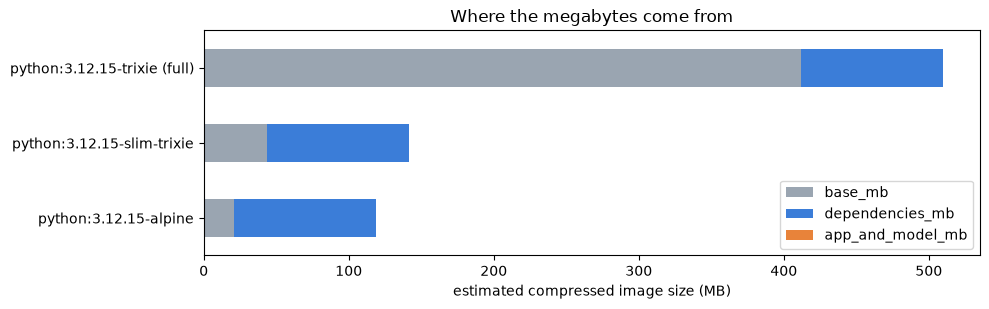

In [14]:
estimate = pd.DataFrame({"base_mb": BASE_IMAGES_MB}).assign(dependencies_mb=deps_mb, app_and_model_mb=app_mb)
estimate["total_mb"] = estimate.sum(axis=1)
estimate["pull_seconds_at_100Mbit"] = (estimate["total_mb"] * 8 / 100).round(0)       # e.g. a new cloud node
print(estimate.round(1))

ax = estimate[["base_mb", "dependencies_mb", "app_and_model_mb"]].plot.barh(stacked=True, figsize=(10, 3.2),
                                                                          color=["#9aa5b1", "#3b7dd8", "#e8833a"])
ax.set_xlabel("estimated compressed image size (MB)"); ax.set_title("Where the megabytes come from")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**What the numbers say:**
- The **full** image is dominated by the base (compilers, headers, docs: useful for building, useless at runtime). Slim saves several hundred MB of download.
- With slim, the **ML dependencies are the biggest part** of the image; SciPy, scikit-learn and NumPy (with their bundled math libraries) top the list. Your own code and this model are negligible. To shrink further, remove dependencies (we already avoided pandas), not code.
- **Alpine** looks smaller still (the estimate simply assumes the same dependency sizes), but it uses *musl* instead of *glibc*: scientific packages need wheels built for musl, and when none exists for your exact version, pip compiles from source (slow builds, needs compilers, sometimes fails). For ML services, `slim` is the usual sweet spot. *Distroless* images (no shell at all) are the next step for security-focused teams.

---
## 13. The exact build / run / test commands (opt-in execution)

These are the commands you would run from the project folder. CI runs the same sequence: tests -> build -> scan -> smoke test the image -> push.

In [15]:
port = CFG.port
COMMANDS = {
    "1. unit tests (before any image)": f"cd {shlex.quote(str(PROJECT))} && pip install -r requirements-dev.txt && pytest -q",
    "2. build (tag with version AND git commit)": f"docker build -t {IMAGE} -t {CFG.registry}/{CFG.name}:$(git rev-parse --short HEAD) .",
    "3. check size and layers": f"docker image ls {CFG.registry}/{CFG.name} && docker history {IMAGE}",
    "4. confirm it is not root": f"docker run --rm --entrypoint id {IMAGE}     # expect uid={CFG.uid}",
    "5. scan for known CVEs": f"docker scout cves {IMAGE}     # or: trivy image {IMAGE}",
    "6. run": f"docker run -d --name house-api -p {port}:{port} --read-only --tmpfs /tmp --env-file .env {IMAGE}",
    "7. smoke test the running container": (f"curl -fsS localhost:{port}/health/ready && curl -fsS -X POST localhost:{port}/v1/predict "
                                            "-H 'Content-Type: application/json' -d '" + json.dumps(smoke.EXAMPLE) + "'"),
    "8. logs, health, stop": "docker logs house-api && docker inspect --format '{{.State.Health.Status}}' house-api && docker rm -f house-api",
    "9. or everything with compose": "cp .env.example .env && docker compose up --build -d && docker compose ps && docker compose down",
    "10. push (CI only)": f"docker push {IMAGE}",
}
for step, command in COMMANDS.items():
    print(f"# {step}\n{command}\n")

# 1. unit tests (before any image)
cd /tmp/containerize_ntxjkyfr/house-price-api && pip install -r requirements-dev.txt && pytest -q

# 2. build (tag with version AND git commit)
docker build -t registry.example.com/ml/house-price-api:1.0.0 -t registry.example.com/ml/house-price-api:$(git rev-parse --short HEAD) .

# 3. check size and layers
docker image ls registry.example.com/ml/house-price-api && docker history registry.example.com/ml/house-price-api:1.0.0

# 4. confirm it is not root
docker run --rm --entrypoint id registry.example.com/ml/house-price-api:1.0.0     # expect uid=10001

# 5. scan for known CVEs
docker scout cves registry.example.com/ml/house-price-api:1.0.0     # or: trivy image registry.example.com/ml/house-price-api:1.0.0

# 6. run
docker run -d --name house-api -p 8000:8000 --read-only --tmpfs /tmp --env-file .env registry.example.com/ml/house-price-api:1.0.0

# 7. smoke test the running container
curl -fsS localhost:8000/health/ready && curl -fsS -X POST localhost

The cell below **would** build the image, start it, call the health endpoint and remove the container again. It only runs when you start Jupyter with `RUN_DOCKER=1` in the environment (and have Docker installed). By default it does nothing, because building images is slow and creates side effects on your machine.

In [16]:
if RUN_DOCKER:                                        # opt-in only: RUN_DOCKER=1 jupyter lab
    import time, urllib.request
    subprocess.run(["docker", "build", "-t", IMAGE, str(PROJECT)], check=True)
    subprocess.run(["docker", "run", "-d", "--name", "house-api-nb", "-p", f"{CFG.port}:{CFG.port}", IMAGE], check=True)
    try:
        time.sleep(5)                                 # give uvicorn a moment to start
        print(urllib.request.urlopen(f"http://127.0.0.1:{CFG.port}/health/ready", timeout=5).read().decode())
    finally:
        subprocess.run(["docker", "rm", "-f", "house-api-nb"], check=False)   # always clean up
else:
    print("RUN_DOCKER is not set to 1: skipping docker build/run. The project is ready in:", PROJECT)

RUN_DOCKER is not set to 1: skipping docker build/run. The project is ready in: /tmp/containerize_ntxjkyfr/house-price-api


---
## 14. From container to Kubernetes, checklist, exercises and resources

**How this image maps to Kubernetes** (see `kubernetes/01_kubernetes.ipynb`):

| In this project | In a Kubernetes Deployment |
|---|---|
| `HEALTHCHECK` on `/health/ready` | **Ignored** by Kubernetes. Use `livenessProbe` -> `/health/live`, `readinessProbe` -> `/health/ready` |
| `USER 10001` | `securityContext: {runAsNonRoot: true, runAsUser: 10001}` |
| compose `read_only: true` | `securityContext: {readOnlyRootFilesystem: true}` + an `emptyDir` for `/tmp` |
| compose `deploy.resources.limits` | `resources: {requests: ..., limits: ...}` |
| `.env` file | a Kubernetes `Secret` (or an external secret manager) mounted as env vars |
| `WEB_CONCURRENCY=2` | often `1`, scaling with replicas + HorizontalPodAutoscaler instead |
| exec-form `CMD` + `--timeout-graceful-shutdown` | graceful pod termination (`terminationGracePeriodSeconds`) |

### Summary

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Pinned base image | `python:3.12.15-slim-trixie` (+ digest in real projects) | Reproducible builds, Renovate/Dependabot updates |
| Pinned + locked dependencies | `requirements.txt` + full `requirements.lock` from the real dependency tree | pip-tools, uv, Poetry lock files |
| Multi-stage build | builder venv -> clean runtime | Nearly every production Dockerfile |
| Cache-friendly layer order | deps -> model -> code | Fast CI builds |
| Non-root, read-only, no-new-privileges | `USER 10001`, compose security options | Kubernetes Pod Security Standards |
| No secrets in images | linter rule + `.dockerignore` + `env_file` | Security reviews, secret scanners |
| Health checks + graceful shutdown | `/health/*`, exec-form `CMD` | Load balancers, orchestrators |
| Policy as code | Dockerfile / compose / requirements checks in Python | hadolint, Trivy, Docker Scout, OPA/Conftest |
| Size awareness | estimate from measured dependency sizes | Faster autoscaling and deploys |

### Practice exercises
1. Add a rule to the linter that flags `apt-get install` without `--no-install-recommends`, and test it on a new bad Dockerfile.
2. Pin the base image to a digest (`docker buildx imagetools inspect python:3.12.15-slim-trixie` prints it) and make the linter accept digests without a patch version.
3. Replace `Ridge` with `HistGradientBoostingRegressor`: does the image size change? (Hint: which packages does it need?) Does the MAE?
4. Write a `livenessProbe` / `readinessProbe` / `securityContext` Kubernetes manifest for this image, then load it with `yaml.safe_load` and write checks for it like `check_compose`.
5. If you have Docker: run with `RUN_DOCKER=1`, compare the real `docker image ls` size with the estimate from Section 12, and explain the difference.

### Resources
- Docker docs: [Building best practices](https://docs.docker.com/build/building/best-practices/), [Multi-stage builds](https://docs.docker.com/build/building/multi-stage/), [.dockerignore](https://docs.docker.com/build/concepts/context/#dockerignore-files), [Compose file reference](https://docs.docker.com/reference/compose-file/)
- FastAPI docs: [FastAPI in Containers - Docker](https://fastapi.tiangolo.com/deployment/docker/)
- [hadolint](https://github.com/hadolint/hadolint) (Dockerfile linter), [Trivy](https://github.com/aquasecurity/trivy) (image scanner)
- [Official python images on Docker Hub](https://hub.docker.com/_/python) (tags and sizes)
- Kubernetes: [Configure liveness, readiness and startup probes](https://kubernetes.io/docs/tasks/configure-pod-container/configure-liveness-readiness-startup-probes/), [Security context](https://kubernetes.io/docs/tasks/configure-pod-container/security-context/)

### Related notebooks in this repo
- `01_docker_basics.ipynb`, `02_docker_for_ml.ipynb` (base images, GPU, compose stack), `03_helm_and_gitops.ipynb`, `kubernetes/01_kubernetes.ipynb`
- `../12_FastAPI/04_industry_production_ml_api.ipynb`: the full production API this container would run
- `../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb`: rolling out a new image version safely
- `../18_Cloud/05_industry_cloud_ml_architecture_and_cost_planning.ipynb`: where to run the container, and what it costs